In [41]:
import pandas as pd
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import mean_squared_error, r2_score, silhouette_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
# Load the wine dataset
wine_r = pd.read_csv("C:/Users/User/Downloads/winequality-red.csv", delimiter=';')
wine_w = pd.read_csv("C:/Users/User/Downloads/winequality-white.csv", delimiter=';')

In [11]:
wine_r.head()
wine_w.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [12]:
# Adding a 'type' column to every dataset
wine_r['type'] = 'red'
wine_w['type'] = 'white'

In [13]:
# Combining datasets
wine_combined = pd.concat([wine_r, wine_w], ignore_index=True)

In [14]:
# Encode the 'type' column
wine_combined['type'] = wine_combined['type'].map({'red': 0, 'white': 1})

In [15]:
wine_combined['quality'] = wine_combined['quality'].replace({3: 4, 9: 8})

In [16]:
# modeling preparation
X = wine_combined.drop('quality', axis=1)
y = wine_combined['quality']

In [17]:
# Splitting the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [18]:
# Setting up cross-validation strategy
cross_val= StratifiedKFold(n_splits=2, shuffle=True, random_state=42)

In [19]:
# Decision Tree Model
decision = DecisionTreeClassifier(random_state=42)
decision_params = {'max_depth': [5, 10, None], 'min_samples_split': [2, 10]}
decision_grid = GridSearchCV(decision, decision_params, cv=cross_val, n_jobs=-1)
decision_grid.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=2, random_state=42, shuffle=True),
             estimator=DecisionTreeClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [5, 10, None],
                         'min_samples_split': [2, 10]})

In [24]:
print("Best Decision Tree Parameters:", decision_grid.best_params_)
decision_best = decision_grid.best_estimator_

Best Decision Tree Parameters: {'max_depth': None, 'min_samples_split': 2}


In [26]:
# Random Forest Model
random = RandomForestClassifier(random_state=42)
random_params = {'n_estimators': [100, 200, 300], 'max_depth': [5, 10, 20, None], 'min_samples_split': [2, 10, 20]}
random_grid = GridSearchCV(random, random_params, cv=5)
random_grid.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42),
             param_grid={'max_depth': [5, 10, 20, None],
                         'min_samples_split': [2, 10, 20],
                         'n_estimators': [100, 200, 300]})

In [27]:
print("Best Random Forest Parameters:", random_grid.best_params_)
random_best = random_grid.best_estimator_

Best Random Forest Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 300}


In [29]:
# SVM Model
svm = SVC(random_state=42)
svm_params = {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}
svm_grid = GridSearchCV(svm, svm_params, cv=cross_val, n_jobs=-1)
svm_grid.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=2, random_state=42, shuffle=True),
             estimator=SVC(random_state=42), n_jobs=-1,
             param_grid={'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']})

In [30]:
print("Best SVM Parameters:", svm_grid.best_params_)
svm_best = svm_grid.best_estimator_

Best SVM Parameters: {'C': 1, 'kernel': 'linear'}


In [31]:
# Evaluating models
model= {'Decision Tree': decision_best, 'SVM': svm_best, 'Random Forest': random_best}

for name, model in model.items():
    y_pred = model.predict(X_test)
    print(f"{name} Model")
    print(classification_report(y_test, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("\n")

Decision Tree Model
              precision    recall  f1-score   support

           4       0.32      0.27      0.29        49
           5       0.66      0.66      0.66       428
           6       0.65      0.66      0.66       567
           7       0.58      0.57      0.58       216
           8       0.46      0.55      0.50        40

    accuracy                           0.63      1300
   macro avg       0.53      0.54      0.54      1300
weighted avg       0.63      0.63      0.63      1300

Confusion Matrix:
 [[ 13  17  13   5   1]
 [ 14 283 109  17   5]
 [ 11 107 373  62  14]
 [  3  16  67 124   6]
 [  0   4   8   6  22]]
Accuracy: 0.6269230769230769


SVM Model
              precision    recall  f1-score   support

           4       0.00      0.00      0.00        49
           5       0.59      0.57      0.58       428
           6       0.50      0.78      0.61       567
           7       0.00      0.00      0.00       216
           8       0.00      0.00      0.00 

C:\Users\User\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\User\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\User\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


Random Forest Model
              precision    recall  f1-score   support

           4       0.50      0.10      0.17        49
           5       0.73      0.72      0.72       428
           6       0.66      0.78      0.72       567
           7       0.70      0.56      0.62       216
           8       0.96      0.55      0.70        40

    accuracy                           0.69      1300
   macro avg       0.71      0.54      0.59      1300
weighted avg       0.69      0.69      0.68      1300

Confusion Matrix:
 [[  5  31  12   1   0]
 [  2 307 115   4   0]
 [  3  78 444  41   1]
 [  0   5  89 122   0]
 [  0   0  11   7  22]]
Accuracy: 0.6923076923076923




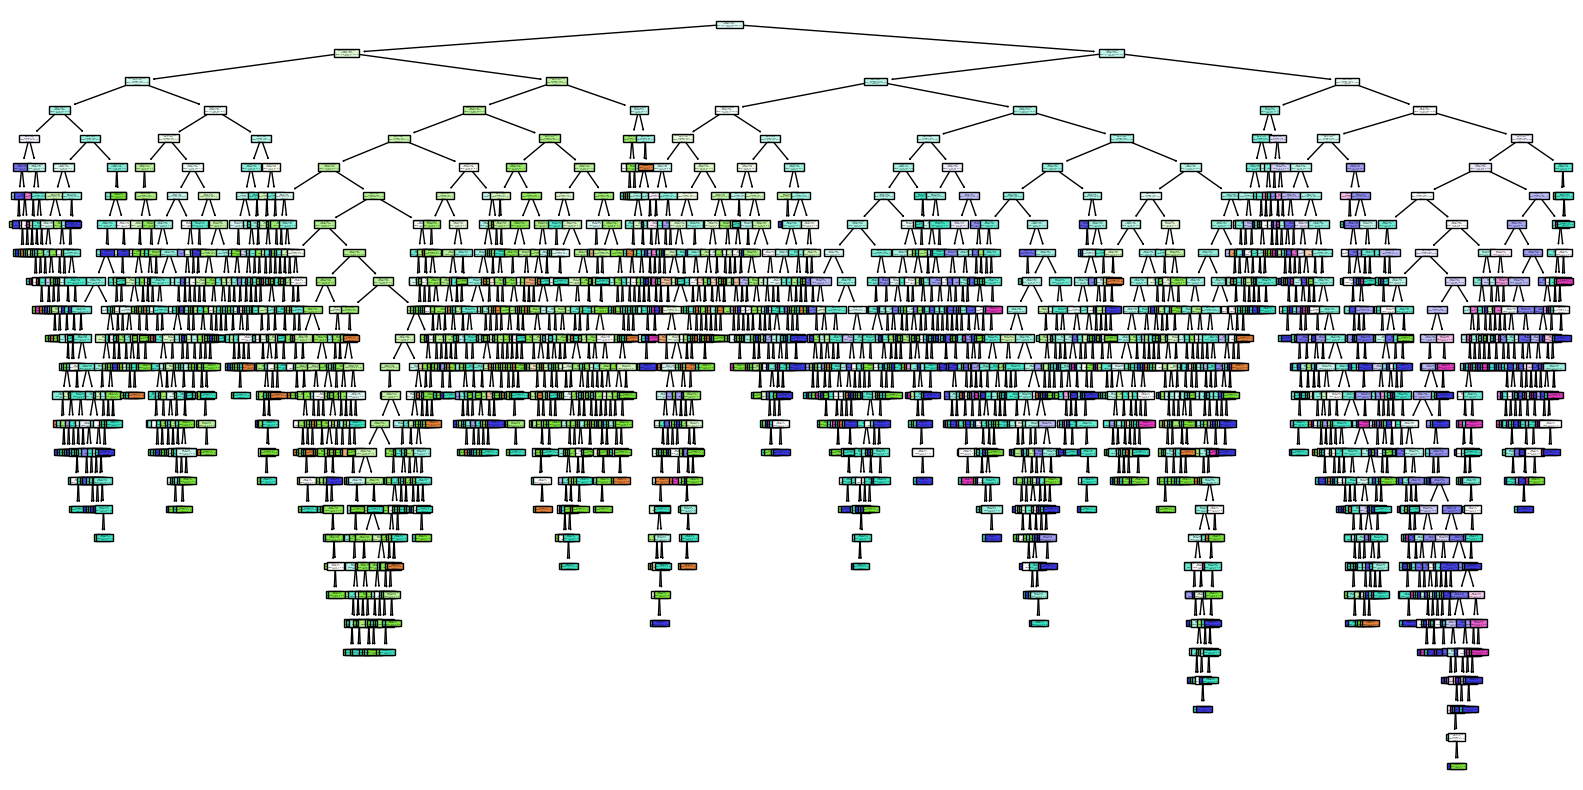

In [32]:
# Plot Decision Tree
plt.figure(figsize=(20,10))
plot_tree(decision_best, feature_names=X.columns, class_names=['3', '4', '5', '6', '7', '8', '9'], filled=True)
plt.show()

In [33]:
# Hierarchical Clustering
hier = AgglomerativeClustering(n_clusters=2)
hier.fit(X)

AgglomerativeClustering()

In [34]:
# KMeans Clustering
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans.fit(X)
kmeans_labels = kmeans.labels_

C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


In [35]:
# Silhouette Score
silhouette_kmeans = silhouette_score(X, kmeans.labels_)
silhouette_hier = silhouette_score(X, hier.labels_)


In [36]:
print("Silhouette Score for K-Means Clustering:", silhouette_kmeans)
print("Silhouette Score for Hierarchical Clustering:", silhouette_hier)

Silhouette Score for K-Means Clustering: 0.509403161565727
Silhouette Score for Hierarchical Clustering: 0.5076934433944243


In [37]:
# Validate Clusters
wine_combined['kmeans_cluster'] = kmeans.labels_
wine_combined['hierarchical_cluster'] = hier.labels_


In [38]:
# Compare Clusters with Labels
accuracy_kmeans = (wine_combined['type'] == wine_combined['kmeans_cluster']).mean()
accuracy_hier = (wine_combined['type'] == wine_combined['hierarchical_cluster']).mean()



In [39]:
print("Accuracy of K-Means Clustering:", accuracy_kmeans)
print("Accuracy of Hierarchical Clustering:", accuracy_hier)

Accuracy of K-Means Clustering: 0.7855933507772819
Accuracy of Hierarchical Clustering: 0.19593658611666923


Text(0.5, 1.0, 'k-means Clustering')

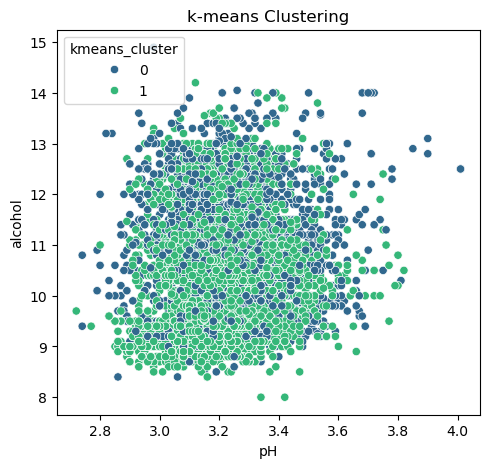

In [42]:
# Visualizing clustering results
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.scatterplot(x='pH', y='alcohol', hue='kmeans_cluster', data=wine_combined, palette='viridis', legend='full')
plt.title('k-means Clustering')

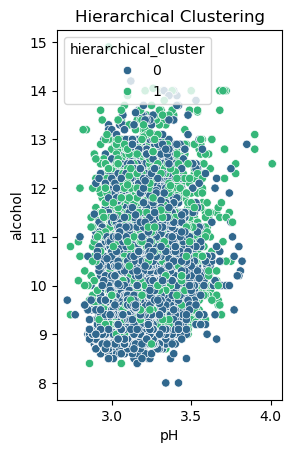

In [43]:
plt.subplot(1, 2, 2)
sns.scatterplot(x='pH', y='alcohol', hue='hierarchical_cluster', data=wine_combined, palette='viridis', legend='full')
plt.title('Hierarchical Clustering')
plt.show()